# Spectral Line Energy Distribution

This example notebook shows how to calculate a model SLED. We consider CO emitted from the ISM of a galaxy. In this simple example, we only vary the kinetic temperature. In a more realistic application, other parameters such as the H$_2$ number density or the column density could also be explored.

In [1]:
from pythonradex import radiative_transfer, helpers
from scipy import constants
import matplotlib.pyplot as plt
import numpy as np

In [2]:
datafilepath = "./co.dat" # file downloaded from EMAA or LAMDA database
geometry = "LVG sphere" #spherical large velocity gradient
line_profile_type = "rectangular"
width_v = 200 * constants.kilo #typical line width for galaxies
source = radiative_transfer.Source(
    datafilepath=datafilepath,
    geometry=geometry,
    line_profile_type=line_profile_type,
    width_v=width_v,
    use_datafile_frequencies=True,
)

We assume a  [CO]/[H$_2$] abundance of $3\times10^{-4}$, a H$_2$ column density of $10^{22}$ cm$^{-2}$, and a H$_2$ number density of $10^3$ cm$^{-3}$

In [3]:
CO_to_H2_abundance = 3e-4
N_H2 = 1e22/constants.centi**2
N_CO = N_H2*CO_to_H2_abundance

#for simplicity, assume ortho/para=1
collider_densities = {
    "para-H2": 0.5e3 / constants.centi**3,
    "ortho-H2": 0.5e3 / constants.centi**3,
}

#assumed the galaxy is at redshift z=1
ext_background = helpers.generate_CMB_background(z=1)

T_dust = tau_dust = 0 # for simplicity, no dust in this example

source.update_parameters(
    N=N_CO,
    Tkin=100, #set arbitrary value here; we will vary it below
    collider_densities=collider_densities,
    ext_background=ext_background,
    T_dust=T_dust,
    tau_dust=tau_dust,
)

Now let us calculate models for a few different kinetic temperatures. We plot the SLED (normalised to CO 1-0) for the ten lowest transitions of CO.

[1.28192875e-09 5.83890496e-09 6.80354971e-09 1.58980562e-09
 5.64605796e-11 8.67549875e-13 9.00970135e-15 6.26395633e-17
 2.57046460e-19 5.92753594e-22]
[1.93591811e-09 1.09714169e-08 1.56658535e-08 7.56952644e-09
 1.12840409e-09 1.18518499e-10 1.05869392e-11 7.15906409e-13
 3.60332542e-14 1.34625256e-15]
[2.42859848e-09 1.75388094e-08 3.26548831e-08 2.74051855e-08
 1.17516442e-08 3.85008803e-09 1.15725488e-09 3.06728720e-10
 7.03107274e-11 1.41395333e-11]
[2.60581894e-09 2.19392746e-08 4.71671508e-08 5.09453612e-08
 3.30587378e-08 1.70167885e-08 8.14434573e-09 3.62109436e-09
 1.47393427e-09 5.57940129e-10]
[2.43030416e-09 2.91401451e-08 7.65194923e-08 1.09727016e-07
 1.06566548e-07 8.48258379e-08 6.22985106e-08 4.43002527e-08
 2.98680959e-08 1.97091573e-08]


/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/radiative_transfer.py:437: UserWarning: negative optical depth! 1-0: tau_nu0 = -0.2
  warnings.warn(warn_message)


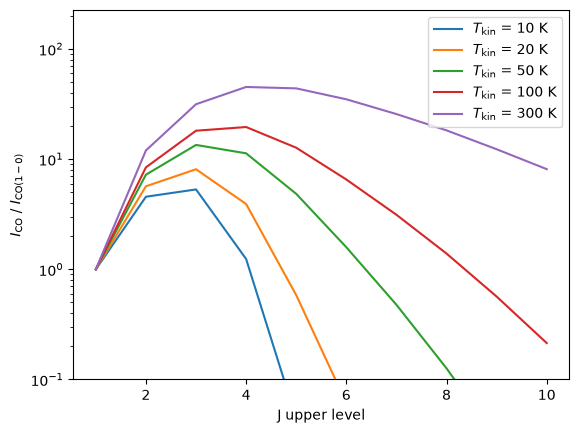

In [4]:
Tkin_values = [10,20,50,100,300]
transition_indices = np.arange(10)
J_upper = transition_indices+1 #verified that this is true in the datafile (co.dat)

fig,ax = plt.subplots()

for Tkin in Tkin_values:
    source.update_parameters(Tkin=Tkin)
    source.solve_radiative_transfer()
    intensities = source.frequency_integrated_emission(
                      output_type="intensity", transitions=transition_indices)
    print(intensities)
    SLED = intensities / intensities[0] #normalise by J=1-0
    ax.plot(J_upper,SLED,label=rf"$T_\mathrm{{kin}}$ = {Tkin} K")

ax.set_xlabel("J upper level")
ax.set_ylabel(r"$I_\mathrm{CO}$ / $I_\mathrm{CO (1-0)}$")
ax.set_yscale("log")
ax.set_ylim(ymin=0.1)
ax.legend(loc="best")

We see how the SLED shifts as the kinetic temperature increases; for higher temperatures, higher J transitions become stronger.